# 03_Key results figure
Rebuilds the numbers behind the four key results in the README and draws them as one 2×2 summary figure. Each panel answers one key result. Requires the Parquet files created in `00_data_overview`.

## 1. Load data

### Register the `pre`, `control`, `treatment` and `user_features` views
Re-run this cell after a kernel restart.

In [8]:
import duckdb

duckdb.sql("SET enable_progress_bar = false")

duckdb.sql("""
CREATE OR REPLACE VIEW pre           AS SELECT * FROM '../data/processed/pre.parquet';
CREATE OR REPLACE VIEW control       AS SELECT * FROM '../data/processed/control.parquet';
CREATE OR REPLACE VIEW treatment     AS SELECT * FROM '../data/processed/treatment.parquet';
CREATE OR REPLACE VIEW user_features AS SELECT * FROM read_csv_auto('../data/raw/KuaiRand-Pure/data/user_features_pure.csv');
""")

## 2. Analysis table

### Build `analysis_table`
Tab-1 impressions with the five metrics, each user's pre-period means (for the balance check), and the pooled activity group from `02`.

In [9]:
duckdb.sql("""
CREATE OR REPLACE TABLE analysis_table AS
WITH i AS (
    -- tab-1 impressions from both groups with a 0/1 treat flag
    SELECT user_id, 1 AS treat,
           long_view, play_time_ms / 1000.0 AS play_sec, is_click, is_like, is_hate
    FROM treatment
    WHERE tab = 1
    UNION ALL
    SELECT user_id, 0 AS treat,
           long_view, play_time_ms / 1000.0 AS play_sec, is_click, is_like, is_hate
    FROM control
    WHERE tab = 1
),
p AS (
    -- each user's tab-1 pre-period means
    SELECT user_id,
           AVG(long_view)             AS pre_long_view,
           AVG(play_time_ms) / 1000.0 AS pre_play_sec,
           AVG(is_click)              AS pre_is_click,
           AVG(is_like)               AS pre_is_like
    FROM pre
    WHERE tab = 1
    GROUP BY user_id
)
SELECT i.*,
       p.pre_long_view, p.pre_play_sec, p.pre_is_click, p.pre_is_like,
       -- pooled activity group, same mapping as 02
       CASE WHEN u.user_active_degree IN ('day_new', '2_14_day_new', '30day_retention') THEN '1_new'
            WHEN u.user_active_degree IN ('low_active', 'single_low_active')             THEN '2_low'
            WHEN u.user_active_degree = 'middle_active'                                  THEN '3_middle'
            WHEN u.user_active_degree = 'high_active'                                    THEN '4_high'
            WHEN u.user_active_degree = 'full_active'                                    THEN '5_full'
       END AS active_group
FROM i
LEFT JOIN p
  ON p.user_id = i.user_id
LEFT JOIN user_features u
  ON u.user_id = i.user_id
""")

# Row count should match 01 (1,401,538)
duckdb.sql("SELECT COUNT(*) AS n_rows FROM analysis_table").show()

┌─────────┐
│ n_rows  │
│  int64  │
├─────────┤
│ 1401538 │
└─────────┘



### Covariate balance
Pre-period means of treatment vs. control impressions, using only impressions with pre-period data. Same numbers as the balance check in `01`.

In [10]:
balance = duckdb.sql("""
SELECT treat,
       AVG(pre_long_view) AS long_view,
       AVG(pre_play_sec)  AS play_sec,
       AVG(pre_is_click)  AS is_click,
       AVG(pre_is_like)   AS is_like
FROM analysis_table
WHERE pre_long_view IS NOT NULL
GROUP BY treat
ORDER BY treat
""").df().set_index('treat')

# percentage difference of treatment relative to control
balance_pct = 100 * (balance.loc[1] / balance.loc[0] - 1)
balance_pct.round(1)

long_view     4.8
play_sec     13.2
is_click      2.4
is_like      -4.4
dtype: float64

## 3. Estimates
Same estimators as `01` and `02`: difference in means and within-user, with standard errors clustered by `user_id`.

In [11]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

df = duckdb.sql("SELECT * FROM analysis_table").df()
metrics = ['long_view', 'play_sec', 'is_click', 'is_like', 'is_hate']


def fit(y, X, groups):
    # OLS with standard errors clustered by user
    res = sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={'groups': groups})
    return res


def demean(d, col):
    # value minus the user's own mean
    return d[col] - d.groupby('user_id')[col].transform('mean')

### Main effect: difference in means vs. within-user

In [12]:
rows = []
t_dm = demean(df, 'treat').rename('treat')
for m in metrics:
    ctrl_mean = df.loc[df['treat'] == 0, m].mean()
    dm = fit(df[m], sm.add_constant(df[['treat']]), df['user_id'])
    fe = fit(demean(df, m), t_dm.to_frame(), df['user_id'])
    rows.append({
        'metric': m,
        'ctrl_mean': ctrl_mean,
        'dm_lift_pct': 100 * dm.params['treat'] / ctrl_mean,
        'fe_lift_pct': 100 * fe.params['treat'] / ctrl_mean,
        'fe_ci_pct':   100 * 1.96 * fe.bse['treat'] / ctrl_mean,   # 95% CI half-width
    })

main = pd.DataFrame(rows).set_index('metric')
main.round(2)

,ctrl_mean,dm_lift_pct,fe_lift_pct,fe_ci_pct
metric,,,,
long_view,0.35,-75.73,-80.46,0.82
play_sec,24.50,-71.57,-78.61,1.05
is_click,0.50,-64.41,-68.57,0.57
is_like,0.02,-75.96,-77.50,4.62
is_hate,0.00,37.56,84.21,32.24


### Play-time cost by activity group
Within-user effect for each pooled activity group, in seconds and relative to the group's control mean.

In [13]:
seg = df.dropna(subset=['active_group'])
y_dm = demean(seg, 'play_sec')
t_seg = demean(seg, 'treat')

levels = sorted(seg['active_group'].unique())
X = pd.DataFrame({lvl: t_seg * (seg['active_group'] == lvl) for lvl in levels})
res = fit(y_dm, X, seg['user_id'])

by_group = pd.DataFrame({
    'ctrl_mean': seg[seg['treat'] == 0].groupby('active_group')['play_sec'].mean(),
    'est':       res.params,
    'ci':        1.96 * res.bse,
}).loc[levels]
by_group['lift_pct'] = 100 * by_group['est'] / by_group['ctrl_mean']

overall_sec = main.loc['play_sec', 'fe_lift_pct'] / 100 * main.loc['play_sec', 'ctrl_mean']
by_group.round(2)

,ctrl_mean,est,ci,lift_pct
1_new,24.94,-18.56,1.54,-74.40
2_low,26.54,-20.20,2.07,-76.12
3_middle,25.65,-19.58,0.78,-76.32
4_high,26.41,-21.06,0.58,-79.75
5_full,23.67,-18.67,0.32,-78.88


## 4. Summary figure
One panel per key result:
- **A.** Effect of a random impression on each metric (within-user vs. naive)
- **B.** Watch-time loss as a function of exploration share
- **C.** Pre-period imbalance that biases the naive estimate
- **D.** Relative vs. absolute play-time cost by activity group

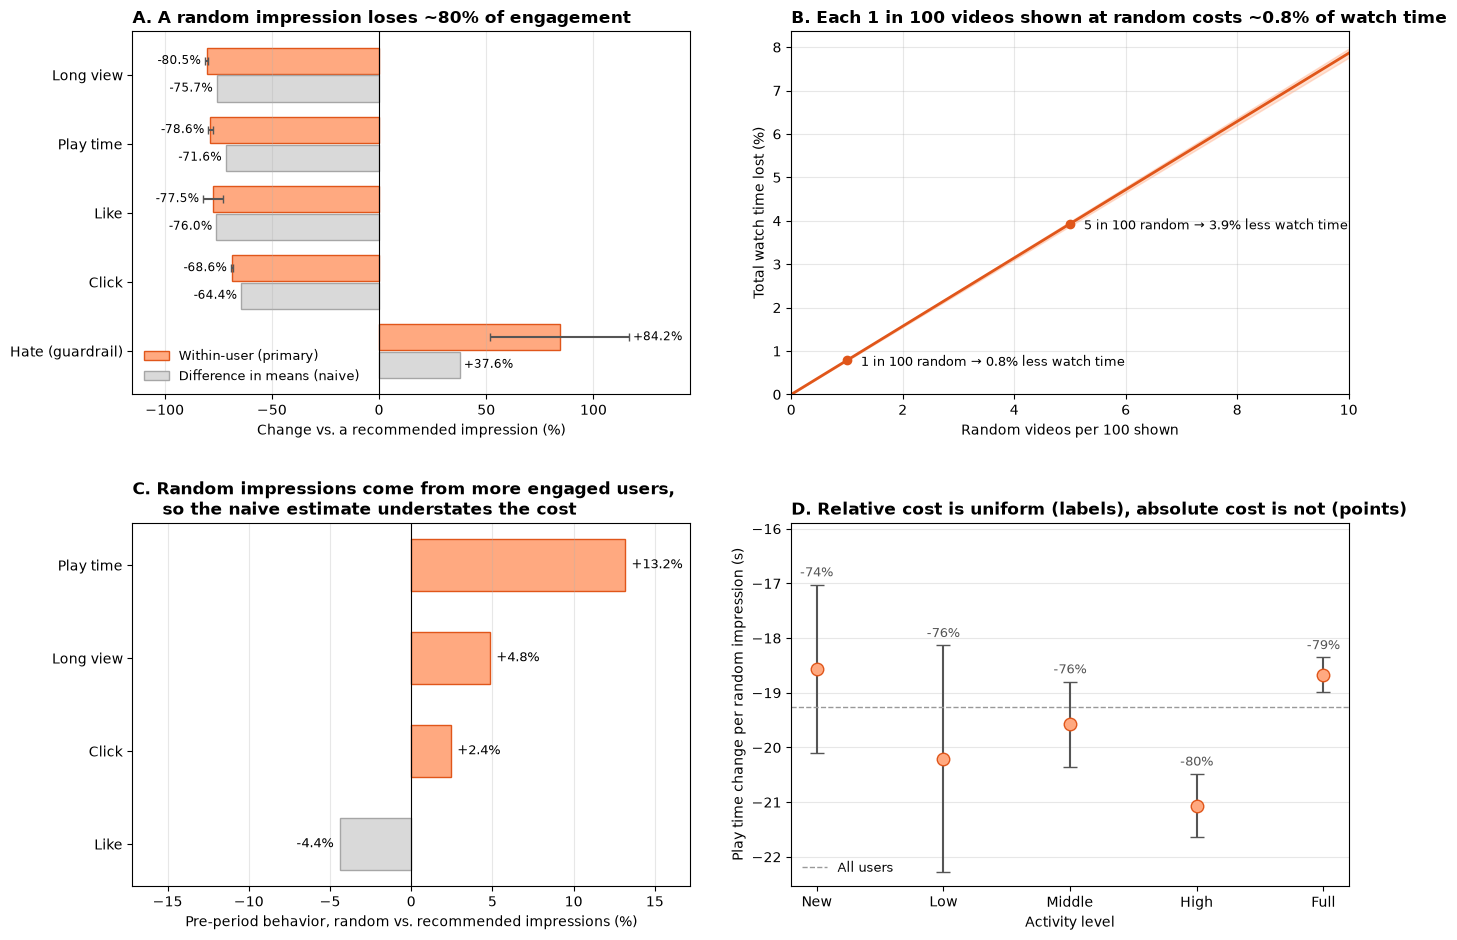

In [14]:
import matplotlib.pyplot as plt
import os

ORANGE, ORANGE_EDGE, GRAY, GRAY_EDGE, DARK = '#FFA980', '#E0561A', '#D9D9D9', '#A6A6A6', '#555555'

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
(ax_a, ax_b), (ax_c, ax_d) = axes

# ---- A. Main effect -------------------------------------------------------
names = {'long_view': 'Long view', 'play_sec': 'Play time', 'is_like': 'Like',
         'is_click': 'Click', 'is_hate': 'Hate (guardrail)'}
a = main.loc[list(names)]
y = np.arange(len(a))
ax_a.barh(y - 0.2, a['fe_lift_pct'], height=0.38, xerr=a['fe_ci_pct'], capsize=3,
          color=ORANGE, edgecolor=ORANGE_EDGE, ecolor=DARK, label='Within-user (primary)')
ax_a.barh(y + 0.2, a['dm_lift_pct'], height=0.38,
          color=GRAY, edgecolor=GRAY_EDGE, label='Difference in means (naive)')
for yi, fe, dm, ci in zip(y, a['fe_lift_pct'], a['dm_lift_pct'], a['fe_ci_pct']):
    for val, offset, pos in [(fe, ci, yi - 0.2), (dm, 0, yi + 0.2)]:
        ax_a.text(val + np.sign(val) * (offset + 2), pos, f'{val:+.1f}%', va='center',
                  ha='left' if val > 0 else 'right', fontsize=8.5)
ax_a.axvline(0, color='black', linewidth=0.8)
ax_a.set_yticks(y, [names[m] for m in a.index])
ax_a.invert_yaxis()
ax_a.set_xlim(-115, 145)
ax_a.set_xlabel('Change vs. a recommended impression (%)')
ax_a.set_title('A. A random impression loses ~80% of engagement', loc='left', fontweight='bold')
ax_a.legend(loc='lower left', frameon=False, fontsize=9)
ax_a.grid(axis='x', alpha=0.3)

# ---- B. Exploration share vs. watch-time loss ------------------------------
lift = -main.loc['play_sec', 'fe_lift_pct']                # positive loss per random impression, %
ci = main.loc['play_sec', 'fe_ci_pct']
share = np.linspace(0, 10, 101)                             # exploration share, % of impressions
ax_b.fill_between(share, share * (lift - ci) / 100, share * (lift + ci) / 100, color=ORANGE, alpha=0.35)
ax_b.plot(share, share * lift / 100, color=ORANGE_EDGE, linewidth=2)
for s in [1, 5]:
    loss = s * lift / 100
    ax_b.plot(s, loss, 'o', color=ORANGE_EDGE)
    ax_b.annotate(f'{s} in 100 random → {loss:.1f}% less watch time', (s, loss),
                  xytext=(10, -4), textcoords='offset points', fontsize=9)
ax_b.set_xlim(0, 10)
ax_b.set_ylim(0, None)
ax_b.set_xlabel('Random videos per 100 shown')
ax_b.set_ylabel('Total watch time lost (%)')
ax_b.set_title(f'B. Each 1 in 100 videos shown at random costs ~{lift / 100:.1f}% of watch time', loc='left', fontweight='bold')
ax_b.grid(alpha=0.3)

# ---- C. Pre-period imbalance -----------------------------------------------
c_names = {'play_sec': 'Play time', 'long_view': 'Long view', 'is_click': 'Click', 'is_like': 'Like'}
c = balance_pct.loc[list(c_names)]
colors = [ORANGE if v > 0 else GRAY for v in c]
edges = [ORANGE_EDGE if v > 0 else GRAY_EDGE for v in c]
ax_c.barh(range(len(c)), c, color=colors, edgecolor=edges, height=0.55)
for yi, val in enumerate(c):
    ax_c.text(val + np.sign(val) * 0.4, yi, f'{val:+.1f}%', va='center',
              ha='left' if val > 0 else 'right', fontsize=9)
ax_c.axvline(0, color='black', linewidth=0.8)
ax_c.set_yticks(range(len(c)), list(c_names.values()))
ax_c.invert_yaxis()
lim = max(abs(c)) + 4
ax_c.set_xlim(-lim, lim)
ax_c.set_xlabel('Pre-period behavior, random vs. recommended impressions (%)')
ax_c.set_title('C. Random impressions come from more engaged users,\n     so the naive estimate understates the cost',
               loc='left', fontweight='bold')
ax_c.grid(axis='x', alpha=0.3)

# ---- D. Relative vs. absolute cost by activity group ------------------------
labels = {'1_new': 'New', '2_low': 'Low', '3_middle': 'Middle', '4_high': 'High', '5_full': 'Full'}
x = [labels.get(lvl, lvl) for lvl in by_group.index]
ax_d.errorbar(x, by_group['est'], yerr=by_group['ci'], fmt='o', markersize=9, capsize=5,
              markerfacecolor=ORANGE, markeredgecolor=ORANGE_EDGE, ecolor=DARK)
for xi, (est, ci_, lp) in enumerate(zip(by_group['est'], by_group['ci'], by_group['lift_pct'])):
    ax_d.annotate(f'{lp:.0f}%', (xi, est + ci_), xytext=(0, 6), textcoords='offset points',
                  ha='center', fontsize=9, color=DARK)
ymin, ymax = ax_d.get_ylim()
ax_d.set_ylim(ymin, ymax + 0.15 * (ymax - ymin))          # headroom for the % labels
ax_d.axhline(overall_sec, color='#999999', linestyle='--', linewidth=1, label='All users')
ax_d.set_xlabel('Activity level')
ax_d.set_ylabel('Play time change per random impression (s)')
ax_d.set_title('D. Relative cost is uniform (labels), absolute cost is not (points)',
               loc='left', fontweight='bold')
ax_d.legend(loc='lower left', frameon=False, fontsize=9)
ax_d.grid(axis='y', alpha=0.3)

plt.tight_layout(h_pad=3, w_pad=3)
os.makedirs('../figures', exist_ok=True)
plt.savefig('../figures/key_results.png', dpi=150, bbox_inches='tight')
plt.show()